In [2]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
from bioframe import overlap
#import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
import gzip
from numpy import diff
from scipy import signal
import scipy.ndimage
from matplotlib.ticker import EngFormatter

In [3]:
# Use bioframe to fetch the genomic features from the UCSC.
hg38_chromsizes = bf.fetch_chromsizes('hg38')
hg38_cens = bf.fetch_centromeres('hg38')
# create a view with chromosome arms using chromosome sizes and definition of centromeres
hg38_arms = bf.make_chromarms(hg38_chromsizes,  hg38_cens)
hg38_arms['arm'] = hg38_arms['name'].str.split('_').str[1]

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amin at 0x14baa893c040> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amax at 0x14baa8933e20> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()


In [4]:
#ES single cell stages (DSG-FA-Plate7):
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/H1-scHiC-DSG-FA-plate7-results/pairs_library"

condition = []
for i in range(1, 97):
    cond = f"scHiC_cell{i}.hg38.nodups.pairs.gz"
    condition.append(cond)
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

ES7_dfs = {}
ES_Num_Contacts7 = {}
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    ES_Num_Contacts7[cond] = Num_Cont
    ES7_dfs[cond] = {'df': df}

    
#ES single cell stages (DSG-FA-Plate8):
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/H1-scHiC-DSG-FA-plate8-results/pairs_library"
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

ES8_dfs = {}
ES_Num_Contacts8 = {}
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    ES_Num_Contacts8[cond] = Num_Cont
    ES8_dfs[cond] = {'df': df}
    
    
    
#combine two plates
ES_DSGFA_dfs = {}

for cond in condition:
    es7_df = ES7_dfs[cond]['df']
    es8_df = ES8_dfs[cond]['df']
    
    ES_DSGFA_dfs[cond] = {'plate1_': es7_df, 'plate2_': es8_df}
    
ES_DSGFA_Contacts = {}
ES_DSGFA_Contacts = {'plate1_': ES_Num_Contacts7, 'plate2_': ES_Num_Contacts8}

In [5]:
#wrong fixation chemistry order, just for fun to test. this dataset wasn't used for following analysis.
#ES single cell stages (FA-DSG-plate5):
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/H1-scHiC-FA-DSG-plate5-results/pairs_library"

condition = []
for i in range(1, 97):
    cond = f"scHiC_cell{i}.hg38.nodups.pairs.gz"
    condition.append(cond)
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

ES5_dfs = {}
ES_Num_Contacts5 = {}
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    ES_Num_Contacts5[cond] = Num_Cont
    ES5_dfs[cond] = {'df': df}

    
#ES single cell stages (FA-DSG-plate6):
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/H1-scHiC-FA-DSG-plate6-results/pairs_library"
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

ES6_dfs = {}
ES_Num_Contacts6 = {}
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    ES_Num_Contacts6[cond] = Num_Cont
    ES6_dfs[cond] = {'df': df}
    
    
#combine two plates
ES_FADSG_dfs = {}

for cond in condition:
    es5_df = ES5_dfs[cond]['df']
    es6_df = ES6_dfs[cond]['df']
    
    ES_FADSG_dfs[cond] = {'plate1_': es5_df, 'plate2_': es6_df}
    
ES_FADSG_Contacts = {}
ES_FADSG_Contacts = {'plate1_': ES_Num_Contacts5, 'plate2_': ES_Num_Contacts6}

In [5]:
import os
import re
import gzip
import pandas as pd

# ============================================================
# Output file
# ============================================================

output_file = (
    "/home/xiangru.huo-umw/scHiC/GEO_processed_data/"
    "ES_plate_based_Batch2_all.pairs.gz"
)

os.makedirs(os.path.dirname(output_file), exist_ok=True)

pairs_header = [
    "read_id",
    "chrom1",
    "pos1",
    "chrom2",
    "pos2",
    "strand1",
    "strand2",
    "pair_type",
    "mapq1",
    "mapq2"
]

# ============================================================
# Dataset information
# ============================================================

datasets = [
    {
        "dataset_id": "Batch2",
        "protocol": "standard",
        "plate_id": "plate7",
        "dfs": ES7_dfs
    },
    {
        "dataset_id": "Batch2",
        "protocol": "standard",
        "plate_id": "plate8",
        "dfs": ES8_dfs
    },
    {
        "dataset_id": "Batch2",
        "protocol": "FA_DSG",
        "plate_id": "plate5",
        "dfs": ES5_dfs
    },
    {
        "dataset_id": "Batch2",
        "protocol": "FA_DSG",
        "plate_id": "plate6",
        "dfs": ES6_dfs
    }
]

cell_type = "H1"

# ============================================================
# Save merged pairs
# ============================================================

total_contacts = 0
total_cells = 0
cell_summary = []

with gzip.open(output_file, "wt") as out:

    out.write("#Combined H1 Batch2 single-cell Hi-C pairs\n")
    out.write(
        "#columns: "
        "cell_id\tcell_type\tdataset_id\tprotocol\tplate_id\t"
        "cell_number\toriginal_cell_id\t"
        + "\t".join(pairs_header)
        + "\n"
    )

    for dataset in datasets:

        dataset_id = dataset["dataset_id"]
        protocol = dataset["protocol"]
        plate_id = dataset["plate_id"]
        dfs = dataset["dfs"]

        print(f"\nProcessing {plate_id} ({protocol})")

        # Loop over all cells in this plate
        for cond in sorted(dfs.keys()):

            original_cell_id = cond.replace(
                ".hg38.nodups.pairs.gz", ""
            )

            # Extract cell number
            match = re.search(r"(\d+)$", original_cell_id)

            if match is None:
                print(f"Skipping {cond}")
                continue

            cell_number = int(match.group(1))

            unique_cell_id = (
                f"{cell_type}_{dataset_id}_{plate_id}_{cell_number}"
            )

            df_out = dfs[cond]["df"].copy()

            # Add metadata columns
            df_out.insert(0, "original_cell_id", original_cell_id)
            df_out.insert(0, "cell_number", cell_number)
            df_out.insert(0, "plate_id", plate_id)
            df_out.insert(0, "protocol", protocol)
            df_out.insert(0, "dataset_id", dataset_id)
            df_out.insert(0, "cell_type", cell_type)
            df_out.insert(0, "cell_id", unique_cell_id)

            # Write to output
            df_out.to_csv(
                out,
                sep="\t",
                index=False,
                header=False
            )

            n_contacts = len(df_out)

            total_contacts += n_contacts
            total_cells += 1

            cell_summary.append({
                "cell_id": unique_cell_id,
                "cell_type": cell_type,
                "dataset_id": dataset_id,
                "protocol": protocol,
                "plate_id": plate_id,
                "cell_number": cell_number,
                "original_cell_id": original_cell_id,
                "n_contacts": n_contacts
            })

            print(
                f"{unique_cell_id:<28} "
                f"{n_contacts:>8,} contacts"
            )

print("\n===================================")
print("Finished!")
print(f"Total cells: {total_cells}")
print(f"Total contacts: {total_contacts:,}")
print(f"Pairs saved to:\n{output_file}")

# ============================================================
# Save cell metadata table
# ============================================================

metadata_file = (
    "/home/xiangru.huo-umw/scHiC/GEO_processed_data/"
    "ES_plate_based_Batch2_all_cell_metadata.tsv"
)

cell_summary_df = pd.DataFrame(cell_summary)

cell_summary_df = cell_summary_df.sort_values(
    ["plate_id", "cell_number"]
)

cell_summary_df.to_csv(
    metadata_file,
    sep="\t",
    index=False
)

print(f"\nMetadata saved to:\n{metadata_file}")

display(cell_summary_df.head())


Processing plate7 (standard)
H1_Batch2_plate7_1             83,618 contacts
H1_Batch2_plate7_10             4,933 contacts
H1_Batch2_plate7_11           105,753 contacts
H1_Batch2_plate7_12             8,633 contacts
H1_Batch2_plate7_13           102,216 contacts
H1_Batch2_plate7_14           117,298 contacts
H1_Batch2_plate7_15            63,459 contacts
H1_Batch2_plate7_16             3,909 contacts
H1_Batch2_plate7_17           113,353 contacts
H1_Batch2_plate7_18            83,506 contacts
H1_Batch2_plate7_19            98,205 contacts
H1_Batch2_plate7_2              5,663 contacts
H1_Batch2_plate7_20           124,954 contacts
H1_Batch2_plate7_21            39,097 contacts
H1_Batch2_plate7_22            24,516 contacts
H1_Batch2_plate7_23             1,623 contacts
H1_Batch2_plate7_24            26,167 contacts
H1_Batch2_plate7_25             6,114 contacts
H1_Batch2_plate7_26           166,465 contacts
H1_Batch2_plate7_27           117,455 contacts
H1_Batch2_plate7_28           

H1_Batch2_plate8_80            34,862 contacts
H1_Batch2_plate8_81             5,472 contacts
H1_Batch2_plate8_82           203,021 contacts
H1_Batch2_plate8_83           162,577 contacts
H1_Batch2_plate8_84             2,922 contacts
H1_Batch2_plate8_85            11,620 contacts
H1_Batch2_plate8_86             7,414 contacts
H1_Batch2_plate8_87               761 contacts
H1_Batch2_plate8_88             5,643 contacts
H1_Batch2_plate8_89             4,348 contacts
H1_Batch2_plate8_9              4,275 contacts
H1_Batch2_plate8_90            12,307 contacts
H1_Batch2_plate8_91             6,711 contacts
H1_Batch2_plate8_92             8,175 contacts
H1_Batch2_plate8_93             1,742 contacts
H1_Batch2_plate8_94             5,666 contacts
H1_Batch2_plate8_95            48,465 contacts
H1_Batch2_plate8_96           478,985 contacts

Processing plate5 (FA_DSG)
H1_Batch2_plate5_1             49,490 contacts
H1_Batch2_plate5_10             1,738 contacts
H1_Batch2_plate5_11             

H1_Batch2_plate6_65             7,710 contacts
H1_Batch2_plate6_66             9,927 contacts
H1_Batch2_plate6_67            11,387 contacts
H1_Batch2_plate6_68             8,547 contacts
H1_Batch2_plate6_69            12,722 contacts
H1_Batch2_plate6_7              2,322 contacts
H1_Batch2_plate6_70            21,955 contacts
H1_Batch2_plate6_71             2,199 contacts
H1_Batch2_plate6_72             6,021 contacts
H1_Batch2_plate6_73             7,186 contacts
H1_Batch2_plate6_74             4,924 contacts
H1_Batch2_plate6_75            10,135 contacts
H1_Batch2_plate6_76            12,361 contacts
H1_Batch2_plate6_77            11,341 contacts
H1_Batch2_plate6_78             8,410 contacts
H1_Batch2_plate6_79            42,664 contacts
H1_Batch2_plate6_8              5,872 contacts
H1_Batch2_plate6_80             8,266 contacts
H1_Batch2_plate6_81            11,477 contacts
H1_Batch2_plate6_82           170,966 contacts
H1_Batch2_plate6_83            27,904 contacts
H1_Batch2_pla

,cell_id,cell_type,dataset_id,protocol,plate_id,cell_number,original_cell_id,n_contacts
192,H1_Batch2_plate5_1,H1,Batch2,FA_DSG,plate5,1,scHiC_cell1,49490
203,H1_Batch2_plate5_2,H1,Batch2,FA_DSG,plate5,2,scHiC_cell2,673
214,H1_Batch2_plate5_3,H1,Batch2,FA_DSG,plate5,3,scHiC_cell3,9519
225,H1_Batch2_plate5_4,H1,Batch2,FA_DSG,plate5,4,scHiC_cell4,14201
236,H1_Batch2_plate5_5,H1,Batch2,FA_DSG,plate5,5,scHiC_cell5,5280


In [6]:
#Define stages
stages = ['FADSG', 'DSGFA']

#organize five stages together
condition_combined_dfs = {}
condition_combined_dfs['FADSG'] = ES_FADSG_dfs
condition_combined_dfs['DSGFA'] = ES_DSGFA_dfs

condition_number = {}
condition_number['FADSG'] = ES_FADSG_Contacts
condition_number['DSGFA'] = ES_DSGFA_Contacts

In [7]:
#caculate the distance and only preserve "chrom1 == chrom 2" (intra-chrom contacts)
condition_contacts_arm_dfs = {stage: {cond: {} for cond in condition} for stage in stages}

for stage in stages:
    for cond in condition:
        for plate in ['plate1_','plate2_']:
            df = condition_combined_dfs[stage][cond][plate].copy()
            df = df[df['chrom1'] == df['chrom2']]
            df['dist'] = df['pos1']-df['pos2']
            df['Abs_Dist'] = abs(df['dist'].copy())
            condition_contacts_arm_dfs[stage][cond][plate] = df

# Plot Mitosis VS interphase

In [8]:
#caculate short-range (1.5Kb-2Mb) and mitotic band (2-12Mb) ratio per cell 
# Initialize dictionaries for ratios and contact counts
short_range_ratio = {stage: {cond: {plate: [] for plate in ['plate1_', 'plate2_']} for cond in condition} for stage in stages}
mitotic_range_ratio = {stage: {cond: {plate: [] for plate in ['plate1_', 'plate2_']} for cond in condition} for stage in stages}
Num_Contacts = {stage: {cond: {plate: [] for plate in ['plate1_', 'plate2_']} for cond in condition} for stage in stages}

# Calculate ratios and store them in dictionaries
for stage in stages:
    for plate in ['plate1_', 'plate2_']:
        i = 0
        for cond in condition:        
            df = condition_contacts_arm_dfs[stage][cond][plate].copy()
            short_range_t = df[(df['Abs_Dist'] > 1500) & (df['Abs_Dist'] < 2000000)]
            mitotic_range_t = df[(df['Abs_Dist'] > 2000000) & (df['Abs_Dist'] < 12000000)]
            Total_incis_1k = df[df['Abs_Dist'] > 1500]
            Num_Con = condition_number[stage][plate][cond]
            i = i + 1
            short_range_ratio_t = len(short_range_t) / (len(Total_incis_1k)+0.001) #imputation incase some cells has 0 contacts
            mitotic_range_ratio_t = len(mitotic_range_t) / (len(Total_incis_1k)+0.001) #imputation incase some cells has 0 contacts
            
            # Append ratios and contact counts to dictionaries
            short_range_ratio[stage][cond][plate].append(short_range_ratio_t)
            mitotic_range_ratio[stage][cond][plate].append(mitotic_range_ratio_t)
            Num_Contacts[stage][cond][plate].append(Num_Con)

In [9]:
# Organize ShortVSMitotic dataframe
ShortVSMitotic = []  
for stage in stages:
    for plate in ['plate1_', 'plate2_']:
        for cond in condition:        
            ShortVSMitotic_t = pd.DataFrame([short_range_ratio[stage][cond][plate], mitotic_range_ratio[stage][cond][plate], Num_Contacts[stage][cond][plate], [stage], [plate],[plate+stage]]).transpose()
            ShortVSMitotic_t.index = [cond]  # Convert cond to a list to match the shape
            ShortVSMitotic_t.columns = ["Short_ratio(1.5K-2Mb)", "Mitotic_ratio(2Mb-12Mb)", "Num_Contacts", "stage", "plate",'plate+stage']
            ShortVSMitotic.append(ShortVSMitotic_t)

# Combine all DataFrames into a single DataFrame
ShortVSMitotic_df = pd.concat(ShortVSMitotic)
ShortVSMitotic_df

,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts,stage,plate,plate+stage
scHiC_cell1.hg38.nodups.pairs.gz,0.542446,0.098996,49490,FADSG,plate1_,plate1_FADSG
scHiC_cell2.hg38.nodups.pairs.gz,0.64704,0.205876,673,FADSG,plate1_,plate1_FADSG
scHiC_cell3.hg38.nodups.pairs.gz,0.598539,0.075426,9519,FADSG,plate1_,plate1_FADSG
scHiC_cell4.hg38.nodups.pairs.gz,0.785956,0.096263,14201,FADSG,plate1_,plate1_FADSG
scHiC_cell5.hg38.nodups.pairs.gz,0.783781,0.092664,5280,FADSG,plate1_,plate1_FADSG
...,...,...,...,...,...,...
scHiC_cell92.hg38.nodups.pairs.gz,0.817974,0.068259,12537,batch1,plate2_,plate2_batch1
scHiC_cell93.hg38.nodups.pairs.gz,0.866991,0.068965,3608,batch1,plate2_,plate2_batch1
scHiC_cell94.hg38.nodups.pairs.gz,0.812686,0.057463,26067,batch1,plate2_,plate2_batch1
scHiC_cell95.hg38.nodups.pairs.gz,0.796447,0.079571,27588,batch1,plate2_,plate2_batch1


In [13]:
import plotly.io as pio
pio.renderers.default = 'notebook'

In [15]:
#filter cells > 30K ,> 50K or > 100K contacts & plot the ratio of short VS mitotic contacts
import plotly.express as px

df = ShortVSMitotic_df[ShortVSMitotic_df['Num_Contacts']>5000]
#df = ShortVSMitotic_df[ShortVSMitotic_df['stage']=='DSGFA']
#df = ShortVSMitotic_df[ShortVSMitotic_df['stage']=='FADSG']

fig = px.scatter(df, x='Mitotic_ratio(2Mb-12Mb)', y='Short_ratio(1.5K-2Mb)', color='plate+stage',
                 title="Short VS mitotic contacts ratio per cell (>5K)")
fig.update_layout(
    autosize=False,
    width=500,
    height=500,
    margin=dict(l=30, r=30, t=30, b=20),
    plot_bgcolor='rgba(0,0,0,0)',  # Set background color to transparent
    paper_bgcolor='rgba(0,0,0,0)'  # Set paper background color to transparent
)

fig.update_layout(
    shapes=[
        dict(
            type='rect',
            xref='x',
            yref='y',
            x0=0,
            y0=0.2,
            x1=0.4,
            y1=1,
            line=dict(color='black', width=1)  # Set line color and width
        ),
        dict(
            type='rect',
            xref='x',
            yref='y',
            x0=0.02,
            y0=0.7,
            x1=0.15,
            y1=0.95,
            line=dict(color='blue', width=1)  # Add a second box with a different color (red)
        ),
        dict(
            type='rect',
            xref='x',
            yref='y',
            x0=0.25,
            y0=0.45,
            x1=0.38,
            y1=0.65,
            line=dict(color='red', width=1)  # Add a second box with a different color (red)
        )
    ]
)

fig.update_traces(
    marker=dict(
        size=5,  # Set the marker size
        opacity=0.8  # Set marker transparency (0 is fully transparent, 1 is opaque)
    )
)


# Show plot
fig.show()
#fig.update_traces(textfont = dict(size = 7))

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/plotly/express/_core.py:1992: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



In [20]:
import plotly.express as px

# Step 1: Filter by contact number
df = ShortVSMitotic_df[ShortVSMitotic_df['Num_Contacts'] > 5000].copy()
df = df[df['stage'] != 'FADSG']

# Step 2: Create a new column for grouping
df['group'] = df['stage'].apply(lambda x: 'batch1' if x == 'batch1' else 'batch2')

# Step 3: Define color mapping
color_map = {
    'batch2': 'orangered',
    'batch1': 'royalblue'
}

# Step 4: Plot
fig = px.scatter(
    df,
    x='Mitotic_ratio(2Mb-12Mb)',
    y='Short_ratio(1.5K-2Mb)',
    color='group',
    color_discrete_map=color_map,
    title="Short VS Mitotic Contacts Ratio per Cell (>5K)"
)

# Step 5: Layout and visual tweaks
fig.update_traces(
    marker=dict(
        size=5,
        opacity=0.8
    )
)

fig.update_layout(
    autosize=False,
    width=500,
    height=500,
    margin=dict(l=30, r=30, t=30, b=20),
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(0,0,0,0)',
    showlegend=True  # Keep legend so we can see which color is which
)

# Step 6: Add reference rectangles
fig.update_layout(
    shapes=[
        dict(type='rect', xref='x', yref='y', x0=0, y0=0.2, x1=0.4, y1=1, line=dict(color='black', width=1)),
        dict(type='rect', xref='x', yref='y', x0=0.02, y0=0.7, x1=0.15, y1=0.95, line=dict(color='blue', width=1)),
        dict(type='rect', xref='x', yref='y', x0=0.25, y0=0.45, x1=0.38, y1=0.65, line=dict(color='red', width=1))
    ]
)

fig.write_image("/home/xiangru.huo-umw/scHiC/scripts/plot/H1_Short VS mitotic contacts ratio per cell (>5K).pdf", 
                width=450, height=400, scale=2, format='pdf')

# Show plot
fig.show()

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/plotly/express/_core.py:1992: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



In [23]:
#save the selected cells
ShortVSMitotic_df = ShortVSMitotic_df[ShortVSMitotic_df['stage'] != 'FADSG'].copy()
#selected interphase or ProM cells dataframe
Interphase_cell_df = ShortVSMitotic_df[(ShortVSMitotic_df['Short_ratio(1.5K-2Mb)'] > 0.6) & (ShortVSMitotic_df['Mitotic_ratio(2Mb-12Mb)'] < 0.15)]
ProM_cell_df = ShortVSMitotic_df[(ShortVSMitotic_df['Short_ratio(1.5K-2Mb)'] < 0.65) & (ShortVSMitotic_df['Mitotic_ratio(2Mb-12Mb)'] > 0.25)]
#selected cell with contacts > 30K 
Interphase_cell_30K = Interphase_cell_df[Interphase_cell_df['Num_Contacts'] > 30000]
ProM_cell_30K = ProM_cell_df[ProM_cell_df['Num_Contacts'] > 30000]
#selected cell with contacts > 20K 
Interphase_cell_20K = Interphase_cell_df[Interphase_cell_df['Num_Contacts'] > 20000]
ProM_cell_20K = ProM_cell_df[ProM_cell_df['Num_Contacts'] > 20000]
#selected cell with contacts > 10K 
Interphase_cell_10K = Interphase_cell_df[Interphase_cell_df['Num_Contacts'] > 10000]
ProM_cell_10K = ProM_cell_df[ProM_cell_df['Num_Contacts'] > 10000]
#selected cell with contacts > 5K 
Interphase_cell_5K = Interphase_cell_df[Interphase_cell_df['Num_Contacts'] > 5000]
ProM_cell_5K = ProM_cell_df[ProM_cell_df['Num_Contacts'] > 5000]

ProM_cell_30K

,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts,stage,plate,plate+stage
scHiC_cell46.hg38.nodups.pairs.gz,0.588126,0.255765,52055,batch1,plate1_,plate1_batch1
scHiC_cell58.hg38.nodups.pairs.gz,0.594854,0.35274,59588,batch1,plate1_,plate1_batch1


In [24]:
Interphase_cell_10K

,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts,stage,plate,plate+stage
scHiC_cell1.hg38.nodups.pairs.gz,0.634784,0.095427,83618,DSGFA,plate1_,plate1_DSGFA
scHiC_cell3.hg38.nodups.pairs.gz,0.70172,0.079462,54996,DSGFA,plate1_,plate1_DSGFA
scHiC_cell4.hg38.nodups.pairs.gz,0.686506,0.109699,203783,DSGFA,plate1_,plate1_DSGFA
scHiC_cell5.hg38.nodups.pairs.gz,0.612395,0.097743,109395,DSGFA,plate1_,plate1_DSGFA
scHiC_cell6.hg38.nodups.pairs.gz,0.730831,0.069456,189120,DSGFA,plate1_,plate1_DSGFA
...,...,...,...,...,...,...
scHiC_cell91.hg38.nodups.pairs.gz,0.831206,0.076546,11921,batch1,plate2_,plate2_batch1
scHiC_cell92.hg38.nodups.pairs.gz,0.817974,0.068259,12537,batch1,plate2_,plate2_batch1
scHiC_cell94.hg38.nodups.pairs.gz,0.812686,0.057463,26067,batch1,plate2_,plate2_batch1
scHiC_cell95.hg38.nodups.pairs.gz,0.796447,0.079571,27588,batch1,plate2_,plate2_batch1


In [25]:
#saving cell info into txt 
##
Interphase_cell_df.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_5stages_2.txt", sep='\t', index=True)
ProM_cell_df.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_proM_cell_5stages_2.txt", sep='\t', index=True)
Interphase_cell_10K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_10K_5stages_2.txt", sep='\t', index=True)
ProM_cell_10K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_proM_cell_10K_5stages_2.txt", sep='\t', index=True)
Interphase_cell_5K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_5K_5stages_2.txt", sep='\t', index=True)
ProM_cell_5K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_proM_cell_5K_5stages_2.txt", sep='\t', index=True)
Interphase_cell_20K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_20K_5stages_2.txt", sep='\t', index=True)
ProM_cell_20K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_proM_cell_20K_5stages_2.txt", sep='\t', index=True)
Interphase_cell_30K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_30K_5stages_2.txt", sep='\t', index=True)
ProM_cell_30K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_proM_cell_30K_5stages_2.txt", sep='\t', index=True)

In [21]:
#load the tables
Interphase_cell_5K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_5K_5stages_2.txt", sep='\t', index_col=0)
Interphase_cell_10K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_10K_5stages_2.txt", sep='\t', index_col=0)
Interphase_cell_20K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_20K_5stages_2.txt", sep='\t', index_col=0)
Interphase_cell_30K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_30K_5stages_2.txt", sep='\t', index_col=0)
Interphase_cell_10K

,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts,stage,plate,plate+stage
scHiC_cell1.hg38.nodups.pairs.gz,0.634784,0.095427,83618,DSGFA,plate1_,plate1_DSGFA
scHiC_cell3.hg38.nodups.pairs.gz,0.701720,0.079462,54996,DSGFA,plate1_,plate1_DSGFA
scHiC_cell4.hg38.nodups.pairs.gz,0.686506,0.109699,203783,DSGFA,plate1_,plate1_DSGFA
scHiC_cell5.hg38.nodups.pairs.gz,0.612395,0.097743,109395,DSGFA,plate1_,plate1_DSGFA
scHiC_cell6.hg38.nodups.pairs.gz,0.730831,0.069456,189120,DSGFA,plate1_,plate1_DSGFA
...,...,...,...,...,...,...
scHiC_cell91.hg38.nodups.pairs.gz,0.831206,0.076546,11921,batch1,plate2_,plate2_batch1
scHiC_cell92.hg38.nodups.pairs.gz,0.817974,0.068259,12537,batch1,plate2_,plate2_batch1
scHiC_cell94.hg38.nodups.pairs.gz,0.812686,0.057463,26067,batch1,plate2_,plate2_batch1
scHiC_cell95.hg38.nodups.pairs.gz,0.796447,0.079571,27588,batch1,plate2_,plate2_batch1


# renew the interphase VS mitosis plot 

In [26]:
#organize ShortVSMitotic table 
#old stages
Interphase_cell_5K_old = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/interphase_cell_5K_5stages_1.txt", sep='\t', index_col=0)
Interphase_cell_5K_old_filter = Interphase_cell_5K_old[(Interphase_cell_5K_old['stage'] != 'H1') & (Interphase_cell_5K_old['stage'] != 'ES')]

#ES stage
H1_ShortVSMitotic = ShortVSMitotic_df.copy()
H1_ShortVSMitotic['stage'] ='ES'
H1_ShortVSMitotic = H1_ShortVSMitotic[H1_ShortVSMitotic['Num_Contacts'] > 5000] 

#concat all
ShortVSMitotic = pd.concat([Interphase_cell_5K_old_filter,H1_ShortVSMitotic])
ShortVSMitotic 

,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts,stage,plate,plate+stage
scHiC_cell3.hg38.nodups.pairs.gz,0.906976,0.042039,10211,DE,plate6_,plate6_DE
scHiC_cell4.hg38.nodups.pairs.gz,0.91569,0.046838,7131,DE,plate6_,plate6_DE
scHiC_cell6.hg38.nodups.pairs.gz,0.898171,0.04047,10183,DE,plate6_,plate6_DE
scHiC_cell8.hg38.nodups.pairs.gz,0.914694,0.047048,66891,DE,plate6_,plate6_DE
scHiC_cell9.hg38.nodups.pairs.gz,0.84741,0.065395,8889,DE,plate6_,plate6_DE
...,...,...,...,...,...,...
scHiC_cell91.hg38.nodups.pairs.gz,0.831206,0.076546,11921,ES,plate2_,plate2_batch1
scHiC_cell92.hg38.nodups.pairs.gz,0.817974,0.068259,12537,ES,plate2_,plate2_batch1
scHiC_cell94.hg38.nodups.pairs.gz,0.812686,0.057463,26067,ES,plate2_,plate2_batch1
scHiC_cell95.hg38.nodups.pairs.gz,0.796447,0.079571,27588,ES,plate2_,plate2_batch1


In [22]:
#plot four stages short-mitotis interaction ratio
#filter cells > 30K ,> 50K or > 100K contacts & plot the ratio of short VS mitotic contacts
import plotly.express as px

# Filter data
df = Interphase_cell_5K_old_filter[Interphase_cell_5K_old_filter['Num_Contacts'] > 10000]

# Define stage-color mapping
stage_colors = {
    'DE': '#386b9f',
    'HB': '#a8c6d9',
    'iHep': '#c3d68a',
    'mHep': '#4d913d'}


# Create scatter plot
fig = px.scatter(
    df,
    x='Mitotic_ratio(2Mb-12Mb)',
    y='Short_ratio(1.5K-2Mb)',
    color='stage',
    color_discrete_map=stage_colors,
    title="Short vs Mitotic Contacts Ratio per Cell (>10K)"
)

# Update layout: transparent background, plot boxes
fig.update_layout(
    autosize=False,
    width=500,
    height=500,
    margin=dict(l=30, r=30, t=30, b=20),
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(0,0,0,0)',
    shapes=[
        dict(type='rect', xref='x', yref='y', x0=0, y0=0.2, x1=0.4, y1=1, line=dict(color='black', width=1)),
        dict(type='rect', xref='x', yref='y', x0=0.02, y0=0.7, x1=0.15, y1=0.95, line=dict(color='blue', width=1)),
        dict(type='rect', xref='x', yref='y', x0=0.25, y0=0.45, x1=0.38, y1=0.65, line=dict(color='red', width=1))
    ]
)

# Adjust marker transparency and size
fig.update_traces(marker=dict(size=5, opacity=0.5))

# Save as PDF
fig.write_image("/home/xiangru.huo-umw/scHiC/scripts/plot/4stages Short VS mitotic contacts ratio per cell (>10K)_combined.pdf", 
                width=450, height=400, scale=2, format='pdf')

fig.show()

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/plotly/express/_core.py:1992: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



In [27]:
#plot five stages short-mitotis interaction ratio
#filter cells > 30K ,> 50K or > 100K contacts & plot the ratio of short VS mitotic contacts
import plotly.express as px

# Filter data
df = ShortVSMitotic[ShortVSMitotic['Num_Contacts'] > 5000]
df = ShortVSMitotic[ShortVSMitotic['Num_Contacts'] > 5000]

# Define stage-color mapping
stage_colors = {
    'ES': '#d99999',
    'DE': '#386b9f',
    'HB': '#a8c6d9',
    'iHep': '#c3d68a',
    'mHep': '#4d913d'}


# Create scatter plot
fig = px.scatter(
    df,
    x='Mitotic_ratio(2Mb-12Mb)',
    y='Short_ratio(1.5K-2Mb)',
    color='stage',
    color_discrete_map=stage_colors,
    title="Short vs Mitotic Contacts Ratio per Cell (>5K)"
)

# Update layout: transparent background, plot boxes
fig.update_layout(
    autosize=False,
    width=500,
    height=500,
    margin=dict(l=30, r=30, t=30, b=20),
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(0,0,0,0)',
    shapes=[
        dict(type='rect', xref='x', yref='y', x0=0, y0=0.2, x1=0.4, y1=1, line=dict(color='black', width=1)),
        dict(type='rect', xref='x', yref='y', x0=0.02, y0=0.7, x1=0.15, y1=0.95, line=dict(color='blue', width=1)),
        dict(type='rect', xref='x', yref='y', x0=0.25, y0=0.45, x1=0.38, y1=0.65, line=dict(color='red', width=1))
    ]
)

# Adjust marker transparency and size
fig.update_traces(marker=dict(size=5, opacity=0.5))

# Save as PDF
fig.write_image("/home/xiangru.huo-umw/scHiC/scripts/plot/Short VS mitotic contacts ratio per cell (>5K)_combined.pdf", 
                width=450, height=400, scale=2, format='pdf')

fig.show()

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/plotly/express/_core.py:1992: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



# count cis/total ratio

In [8]:
#get compartment files (100kb) of 5 stages of bulk HiC (rep 2)
#path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/compartment_bulk"
path = '/pi/job.dekker-umw/home/johan.gibcus-umw/projects/UM1/compartments'
os.chdir(path)
os.getcwd()

comp = pd.read_csv('ESC-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)

print(len(comp.dropna()))

26984


In [9]:
#compartment A/B separated into two parts 
comp_A = {}
comp_B = {}

comp_A = comp[comp['E1']>0]
comp_B = comp[comp['E1']<0]
comp_A = comp_A.loc[:,['chrom','start','end']]
comp_A['comp'] = 'A'
comp_B = comp_B.loc[:,['chrom','start','end']]
comp_B['comp'] = 'B'

In [10]:
#identify unique_chrom_value
unique_chrom = comp['chrom'].unique()
#remove chrM from unique_chrom
unique_chrom_nuclei = unique_chrom[:-1]

In [11]:
#split comp_combine table by different chromosomes
def split_df_by_chrom(df):
    # Get unique chromosome values
    unique_chrom_values = df['chrom'].unique()
    
    # Create a dictionary to store the split DataFrames
    split_dfs = {}
    
    # Iterate over unique chromosome values
    for chrom_value in unique_chrom_values:
        # Extract rows with the current chromosome value
        split_df = df[df['chrom'] == chrom_value].copy()
         # Reset index
        split_df.reset_index(drop=True, inplace=True)
        # Store the DataFrame in the dictionary
        split_dfs[chrom_value] = split_df
    return split_dfs

In [12]:
#apply "split_df_by_chrom" function 
comp_split = split_df_by_chrom(comp)

In [13]:
#define a bin combine function (1M = 10, 2M = 20)
def create_continuous_ranges(df, Mg):
    original_list = df.index 
    # Split the indices into lists of length Mg
    index_lists = [original_list[i:i+Mg] for i in range(0, len(original_list), Mg)]

    df_Mg = pd.DataFrame(columns=["chrom", "start", "end", "E1"])
    
    # Loop through the index_lists
    for indices in index_lists:
        start_index = indices[0]
        end_index = indices[-1]       
        # Create a temporary DataFrame for the current continuous range
        df_continues_tmp = pd.DataFrame({
            "chrom": [df['chrom'][start_index]],
            "start": [df['start'][start_index]],
            "end": [df['end'][end_index]],
            "E1": [df['E1'][start_index:end_index].mean()]
        })        
        # Concatenate the temporary DataFrame to the main DataFrame
        df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
        df_Mg['start'] = df_Mg['start'].astype(int)
        df_Mg['end'] = df_Mg['end'].astype(int)
        df_Mg['E1'] = df_Mg['E1'].astype(float)
    
    # Add a Bin_ID column to the DataFrame
    df_Mg["Bin_ID"] = df_Mg["chrom"] + "_Bin" + df_Mg.index.astype(str)
    
    return df_Mg

In [14]:
#apply "create_continuous_ranges" function on comp_split
comp_chrom_bin = {}
for chrom in unique_chrom_nuclei:
    comp_chrom_bin[chrom] = create_continuous_ranges(comp_split[chrom], 10)

/tmp/ipykernel_1361054/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_1361054/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_1361054/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or 

In [15]:
#get comp bin all 
comp_bin = pd.concat(comp_chrom_bin.values(), ignore_index=True)

In [16]:
comp_bin

,chrom,start,end,E1,Bin_ID
0,chr1,0,1000000,NaN,chr1_Bin0
1,chr1,1000000,2000000,0.827367,chr1_Bin1
2,chr1,2000000,3000000,0.503929,chr1_Bin2
3,chr1,3000000,4000000,0.436396,chr1_Bin3
4,chr1,4000000,5000000,0.291384,chr1_Bin4
...,...,...,...,...,...
3097,chrY,53000000,54000000,NaN,chrY_Bin53
3098,chrY,54000000,55000000,NaN,chrY_Bin54
3099,chrY,55000000,56000000,NaN,chrY_Bin55
3100,chrY,56000000,57000000,0.055821,chrY_Bin56


In [17]:
#re-organize contacts map into correct order
contacts_reorganized = {stage: {plate: {} for plate in ['plate1_','plate2_']} for stage in stages}
contact_dist = 300

for stage in stages:
    for cond in condition:
        for plate in ['plate1_','plate2_']:
            df = condition_combined_dfs[stage][cond][plate].copy()
            df_filtered = df[(df['chrom1'] != df['chrom2']) |  # Keep rows where chrom1 != chrom2
                            ((df['chrom1'] == df['chrom2']) & ((df['pos2'] - df['pos1']).abs() >= contact_dist))] # Keep rows where chrom1 == chrom2 and pos2 - pos1 > 100000
            contacts_reorganized[stage][plate][cond] = df_filtered

In [18]:
contacts_reorganized[stage][plate][cond]

,read_id,chrom1,pos1,chrom2,pos2,strand1,strand2,pair_type,mapq1,mapq2
1,LH00401:376:22NH33LT4:8:1167:25787:21689,chr1,820514,chr1,823600,+,-,UU,9,42
2,LH00401:376:22NH33LT4:8:1484:25398:24771,chr1,820595,chr1,822924,-,+,UU,10,60
7,LH00401:376:22NH33LT4:8:1101:31540:13971,chr1,822924,chr1,823600,+,-,UU,60,60
12,LH00401:376:22NH33LT4:8:2478:6624:12332,chr1,847926,chr1,848396,+,-,UU,3,29
13,LH00401:376:22NH33LT4:8:1104:43282:20653,chr1,847926,chr1,848406,+,-,UU,32,41
...,...,...,...,...,...,...,...,...,...,...
478979,LH00401:376:22NH33LT4:8:1363:52151:6393,chrY,56858287,chrY,56858686,+,-,UU,60,60
478981,LH00401:376:22NH33LT4:8:2418:21182:22208,chrY,56873857,chrY,56874561,+,-,UU,41,6
478982,LH00401:376:22NH33LT4:8:1103:36711:22782,chrY,56873857,chrY,56874564,+,-,UU,43,7
478983,LH00401:376:22NH33LT4:8:1115:25261:11310,chrY,56874255,chrY,56874564,+,-,UU,32,7


In [19]:
#generate bin id to each contacts per cell
def generate_contacts_bin_id(df):
    # Process 'chrom1' and 'pos1'
    df1 = df[['chrom1', 'pos1']].copy()
    df1.rename(columns={'chrom1': 'chrom', 'pos1': 'start'}, inplace=True)
    df1['end'] = df1['start'] + 1
    df1_binID = bf.overlap(df1, comp_bin, how='left', suffixes=('_1', '_2'))
    df1_binID = df1_binID.loc[:, ['chrom_1', 'start_1', 'Bin_ID_2']].copy()
    df1_binID.columns = ['chrom1', 'pos1', 'Bin_ID_1']

    # Process 'chrom2' and 'pos2'
    df2 = df[['chrom2', 'pos2']].copy()
    df2.rename(columns={'chrom2': 'chrom', 'pos2': 'start'}, inplace=True)
    df2['end'] = df2['start'] + 1
    df2_binID = bf.overlap(df2, comp_bin, how='left', suffixes=('_1', '_2'))
    df2_binID = df2_binID.loc[:, ['chrom_1', 'start_1', 'Bin_ID_2']].copy()
    df2_binID.columns = ['chrom2', 'pos2', 'Bin_ID_2']

    # Concatenate the results
    df_binID = pd.concat([df1_binID, df2_binID], axis=1)

    return df_binID

In [25]:
#Build dictionary of interphase cells (here i used 10K or 30K contacts cells to plot scaling)
#load the tables
Interphase_cell_5K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_5K_5stages_2.txt", sep='\t', index_col=0)
Interphase_cell_10K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_10K_5stages_2.txt", sep='\t', index_col=0)
Interphase_cell_20K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_20K_5stages_2.txt", sep='\t', index_col=0)
Interphase_cell_30K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/H1_interphase_cell_30K_5stages_2.txt", sep='\t', index_col=0)


Interphase_30K_dict = {}
for stage in Interphase_cell_30K['stage'].unique():
    stage_df = Interphase_cell_30K[Interphase_cell_30K['stage'] == stage]
    plate_dict = {}
    for plate in stage_df['plate'].unique():
        indices = stage_df[stage_df['plate'] == plate].index.tolist()
        plate_dict[plate] = indices
    Interphase_30K_dict[stage] = plate_dict
    
Interphase_20K_dict = {}
for stage in Interphase_cell_20K['stage'].unique():
    stage_df = Interphase_cell_20K[Interphase_cell_20K['stage'] == stage]
    plate_dict = {}
    for plate in stage_df['plate'].unique():
        indices = stage_df[stage_df['plate'] == plate].index.tolist()
        plate_dict[plate] = indices
    Interphase_20K_dict[stage] = plate_dict

In [26]:
# Call the function "generate_contacts_Bin_id" and store the result
stage_contacts_Bin_ID = {stage: {plate: {} for plate in ['plate1_','plate2_']} for stage in stages}
stages = ['DSGFA']

for stage in stages:
    for plate in ['plate1_','plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = contacts_reorganized[stage][plate][cond].copy()
            stage_contacts_Bin_ID[stage][plate][cond] = generate_contacts_bin_id(df)

In [52]:
df =stage_contacts_Bin_ID[stage][plate][cond].copy()
df2 = pd.DataFrame(df.groupby('Bin_ID_2')['chrom1'].value_counts())
df2.head(10)

count
Bin_ID_2     chrom1       
chr10_Bin0   chr1        2
             chr2        1
chr10_Bin1   chr10       2
chr10_Bin10  chr10       1
             chr3        1
chr10_Bin100 chr1        1
chr10_Bin101 chr1        3
chr10_Bin102 chr4        1
             chr7        1
             chr9        1

In [53]:
unique_chrom1_counts = df.groupby('Bin_ID_2')['chrom1'].nunique().reset_index()

# Rename for clarity
unique_chrom1_counts.columns = ['Bin_ID_2', 'chromosome_count']

# Preview
unique_chrom1_counts.head(10)

,Bin_ID_2,chromosome_count
0,chr10_Bin0,2
1,chr10_Bin1,1
2,chr10_Bin10,2
3,chr10_Bin100,1
4,chr10_Bin101,1
5,chr10_Bin102,3
6,chr10_Bin103,2
7,chr10_Bin104,3
8,chr10_Bin105,1
9,chr10_Bin106,1


In [27]:
#define the function to get the cis_ratio per cell + count of inter-chromsomes 
def calculate_cis_ratio(df):
    # From pos1 (Bin_ID_1)
    cis_count = df.groupby('Bin_ID_1')['chrom2'].apply(lambda x: x.value_counts().max()).reset_index()
    total_count = df.groupby('Bin_ID_1')['chrom2'].apply(lambda x: x.value_counts().sum()).reset_index()
    
    cis_ratio = pd.merge(cis_count, total_count, on='Bin_ID_1', how='outer')
    cis_ratio.columns = ['Bin_ID_1', 'cis_count1', 'total_count1']
    cis_ratio['trans_count1'] = cis_ratio['total_count1'] - cis_ratio['cis_count1']

    # From pos2 (Bin_ID_2)
    cis_count2 = df.groupby('Bin_ID_2')['chrom1'].apply(lambda x: x.value_counts().max()).reset_index()
    total_count2 = df.groupby('Bin_ID_2')['chrom1'].apply(lambda x: x.value_counts().sum()).reset_index()
    
    cis_ratio2 = pd.merge(cis_count2, total_count2, on='Bin_ID_2', how='outer')
    cis_ratio2.columns = ['Bin_ID_1', 'cis_count2', 'total_count2']
    cis_ratio2['trans_count2'] = cis_ratio2['total_count2'] - cis_ratio2['cis_count2']

    # 🔹 NEW: Unique chrom1 count per Bin_ID_2 (renamed to Bin_ID_1 for merging)
    unique_chrom1 = df.groupby('Bin_ID_2')['chrom1'].nunique().reset_index()
    unique_chrom1.columns = ['Bin_ID_1', 'Chromosome_counts']

    # Combine all
    cis_ratio_all = pd.merge(cis_ratio, cis_ratio2, on='Bin_ID_1', how='outer')
    cis_ratio_all = pd.merge(cis_ratio_all, unique_chrom1, on='Bin_ID_1', how='left')

    # Final computed columns
    cis_ratio_all['cis_count_final'] = cis_ratio_all[['cis_count1', 'cis_count2']].max(axis=1)
    cis_ratio_all['trans_count_final'] = cis_ratio_all['trans_count1'] + cis_ratio_all['trans_count2']
    cis_ratio_all['total_count_final'] = cis_ratio_all['cis_count_final'] + cis_ratio_all['trans_count_final']
    cis_ratio_all['cis_ratio_final'] = cis_ratio_all['cis_count_final'] / cis_ratio_all['total_count_final']

    return cis_ratio_all

In [28]:
# Call the function "calculate_cis_ratio" and store the result
stage_cis_ratio_Bin_ID = {stage: {plate: {} for plate in ['plate1_','plate2_']} for stage in stages}

for stage in stages:
    for plate in ['plate1_','plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = stage_contacts_Bin_ID[stage][plate][cond].copy()
            stage_cis_ratio_Bin_ID[stage][plate][cond] = calculate_cis_ratio(df)

In [29]:
stage_cis_ratio_Bin_ID[stage][plate][cond]

,Bin_ID_1,cis_count1,total_count1,trans_count1,cis_count2,total_count2,trans_count2,Chromosome_counts,cis_count_final,trans_count_final,total_count_final,cis_ratio_final
0,chr10_Bin0,103.0,135.0,32.0,120.0,233.0,113.0,7.0,120.0,145.0,265.0,0.452830
1,chr10_Bin1,75.0,86.0,11.0,69.0,141.0,72.0,7.0,75.0,83.0,158.0,0.474684
2,chr10_Bin10,85.0,96.0,11.0,83.0,145.0,62.0,6.0,85.0,73.0,158.0,0.537975
3,chr10_Bin100,152.0,179.0,27.0,170.0,360.0,190.0,10.0,170.0,217.0,387.0,0.439276
4,chr10_Bin101,104.0,117.0,13.0,111.0,226.0,115.0,9.0,111.0,128.0,239.0,0.464435
...,...,...,...,...,...,...,...,...,...,...,...,...
2945,chrY_Bin56,16.0,24.0,8.0,20.0,40.0,20.0,9.0,20.0,28.0,48.0,0.416667
2946,chrY_Bin6,40.0,41.0,1.0,52.0,113.0,61.0,16.0,52.0,62.0,114.0,0.456140
2947,chrY_Bin7,48.0,48.0,0.0,85.0,189.0,104.0,16.0,85.0,104.0,189.0,0.449735
2948,chrY_Bin8,35.0,35.0,0.0,33.0,79.0,46.0,16.0,35.0,46.0,81.0,0.432099


In [78]:
##concatenate cis_ratio_all['cis_ratio_final'] for per cell, and organize per stage into a matrix

In [30]:
#get sum of cis_total ratio Bin_ID per cell
cis_ratio_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})
    for plate in ['plate1_', 'plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = stage_cis_ratio_Bin_ID[stage][plate][cond]
            df_tmp = df[['Bin_ID_1', 'cis_ratio_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', plate + cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    cis_ratio_Bin_ID_sum[stage] = df_sum  

In [31]:
#get sum of cis_total ratio Bin_ID per cell
cis_ratio_Bin_ID_sum2 = {stage: {plate: {} for plate in ['plate6_', 'plate8_']} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})
    for plate in ['plate1_', 'plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = stage_cis_ratio_Bin_ID[stage][plate][cond]
            df_tmp = df[['Bin_ID_1', 'cis_ratio_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', plate + cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
        df_sum = df_sum.set_index('Bin_ID_1')
        cis_ratio_Bin_ID_sum2[stage][plate] = df_sum  

In [32]:
cis_ratio_Bin_ID_sum[stage]

,plate1_scHiC_cell1.hg38.nodups.pairs.gz,plate1_scHiC_cell3.hg38.nodups.pairs.gz,plate1_scHiC_cell4.hg38.nodups.pairs.gz,plate1_scHiC_cell5.hg38.nodups.pairs.gz,plate1_scHiC_cell6.hg38.nodups.pairs.gz,plate1_scHiC_cell7.hg38.nodups.pairs.gz,plate1_scHiC_cell8.hg38.nodups.pairs.gz,plate1_scHiC_cell9.hg38.nodups.pairs.gz,plate1_scHiC_cell11.hg38.nodups.pairs.gz,plate1_scHiC_cell13.hg38.nodups.pairs.gz,...,plate2_scHiC_cell43.hg38.nodups.pairs.gz,plate2_scHiC_cell44.hg38.nodups.pairs.gz,plate2_scHiC_cell69.hg38.nodups.pairs.gz,plate2_scHiC_cell70.hg38.nodups.pairs.gz,plate2_scHiC_cell73.hg38.nodups.pairs.gz,plate2_scHiC_cell79.hg38.nodups.pairs.gz,plate2_scHiC_cell80.hg38.nodups.pairs.gz,plate2_scHiC_cell82.hg38.nodups.pairs.gz,plate2_scHiC_cell95.hg38.nodups.pairs.gz,plate2_scHiC_cell96.hg38.nodups.pairs.gz
Bin_ID_1,,,,,,,,,,,,,,,,,,,,,
chr10_Bin0,0.416667,1.000000,0.627907,0.538462,0.409091,0.769231,0.400000,NaN,0.538462,0.545455,...,0.500000,0.666667,0.708333,1.000000,0.857143,0.818182,0.529412,0.551724,0.600000,0.452830
chr10_Bin1,0.222222,0.500000,0.641026,0.547619,0.454545,0.666667,0.500000,1.0,0.363636,0.478261,...,0.500000,1.000000,0.933333,0.880952,0.461538,0.483871,0.750000,0.512821,0.695652,0.474684
chr10_Bin10,0.846154,0.545455,0.585366,1.000000,0.638889,0.642857,0.727273,0.5,0.636364,1.000000,...,0.577778,1.000000,0.555556,0.800000,0.562500,0.750000,0.666667,0.487179,0.444444,0.537975
chr10_Bin100,0.640000,0.545455,0.596154,0.571429,0.461538,0.777778,0.439024,1.0,0.627907,0.490909,...,1.000000,0.875000,0.833333,0.666667,0.631579,0.863636,0.750000,0.477612,0.666667,0.439276
chr10_Bin101,0.500000,NaN,0.454545,0.545455,0.612500,0.411765,0.619048,1.0,0.750000,0.538462,...,1.000000,0.500000,0.530120,0.800000,0.500000,0.500000,1.000000,0.479167,0.529412,0.464435
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin6,NaN,NaN,0.500000,0.565217,0.562500,NaN,NaN,NaN,0.424242,0.666667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.333333,0.500000,0.456140
chrY_Bin7,0.400000,0.500000,0.437500,0.444444,0.571429,NaN,1.000000,NaN,0.666667,0.769231,...,NaN,1.000000,0.500000,0.857143,0.750000,1.000000,1.000000,0.467742,0.500000,0.449735


In [33]:
#get sum of total reads of Bin_ID per cell
reads_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})
    for plate in ['plate1_', 'plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = stage_cis_ratio_Bin_ID[stage][plate][cond]
            df_tmp = df[['Bin_ID_1', 'total_count_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', plate + cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    reads_Bin_ID_sum[stage] = df_sum  

In [34]:
#get sum of total reads of Bin_ID per cell
reads_Bin_ID_sum2 = {stage: {plate: {} for plate in ['plate6_', 'plate8_']} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})
    for plate in ['plate1_', 'plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = stage_cis_ratio_Bin_ID[stage][plate][cond]
            df_tmp = df[['Bin_ID_1', 'total_count_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', plate + cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
        df_sum = df_sum.set_index('Bin_ID_1')
        reads_Bin_ID_sum2[stage][plate] = df_sum  

In [35]:
#get sum of total cis_count_final of Bin_ID per cell
cis_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})
    for plate in ['plate1_', 'plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = stage_cis_ratio_Bin_ID[stage][plate][cond]
            df_tmp = df[['Bin_ID_1', 'cis_count_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', plate + cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    cis_Bin_ID_sum[stage] = df_sum  

In [36]:
#get sum of total trans_count_final of Bin_ID per cell
trans_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})
    for plate in ['plate1_', 'plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = stage_cis_ratio_Bin_ID[stage][plate][cond]
            df_tmp = df[['Bin_ID_1', 'trans_count_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', plate + cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    trans_Bin_ID_sum[stage] = df_sum  

In [37]:
#get sum of total interact chromosomes of Bin_ID per cell
chromnum_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})
    for plate in ['plate1_', 'plate2_']:
        for cond in Interphase_20K_dict[stage][plate]:
            df = stage_cis_ratio_Bin_ID[stage][plate][cond]
            df_tmp = df[['Bin_ID_1', 'Chromosome_counts']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', plate + cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    chromnum_Bin_ID_sum[stage] = df_sum  

In [38]:
# Initialize dictionary
stage_cis_ratio_Bin_ID_sum = {}

# Apply prefix and transpose for each stage
for stage in ['DSGFA']:
    stage_cis_ratio_Bin_ID_sum[stage] = cis_ratio_Bin_ID_sum[stage].add_prefix(f'{stage}_').transpose()
# Concatenate across stages
stage_cis_ratio_Bin_ID = pd.concat(stage_cis_ratio_Bin_ID_sum.values(), ignore_index=True)

In [39]:
#organized H1 and ES together total counts
stage_reads_Bin_ID_sum = {}
stage_reads_Bin_ID_sum['DSGFA'] = reads_Bin_ID_sum['DSGFA'].add_prefix('DSGFA_').transpose()

In [40]:
#organized H1 and ES together cis counts
stage_cis_Bin_ID_sum = {}
stage_cis_Bin_ID_sum['DSGFA'] = cis_Bin_ID_sum['DSGFA'].add_prefix('DSGFA_').transpose()

In [41]:
#save stage_cis_ratio_Bin_ID_sum into .csv (needs to take care 1M or 2M)
# Concatenate and KEEP index
stage_cis_ratio_Bin_ID = pd.concat(stage_cis_ratio_Bin_ID_sum.values())
stage_reads_Bin_ID = pd.concat(stage_reads_Bin_ID_sum.values())
stage_cis_Bin_ID = pd.concat(stage_cis_Bin_ID_sum.values())

# Save concatenated tables (keep index in the file)
stage_cis_ratio_Bin_ID.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/cis_ratio_perBin_H1_1M_batch2>0.3kb.txt', sep='\t', index=True)
stage_reads_Bin_ID.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_reads_perBin_H1_1M_batch2>0.3kb.txt', sep='\t', index=True)
stage_cis_Bin_ID.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_cis_perBin_H1_1M_batch2>0.3kb.txt', sep='\t', index=True)

In [43]:
#read files
stage_cis_ratio_Bin_ID_batch2 = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/cis_ratio_perBin_H1_1M_batch2>0.3kb.txt', sep='\t',index_col=0)
stage_reads_Bin_ID_batch2 = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_reads_perBin_H1_1M_batch2>0.3kb.txt', sep='\t',index_col=0)
stage_cis_Bin_ID_batch2 = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_cis_perBin_H1_1M_batch2>0.3kb.txt', sep='\t',index_col=0)

In [44]:
#for batch 2 files
df = comp_bin.copy()
df.set_index('Bin_ID', inplace=True)
df['cisratio_mean'] = stage_cis_ratio_Bin_ID_batch2.mean()
df['cisratio_S.D.'] = stage_cis_ratio_Bin_ID_batch2.std()
df['cisratio_cv'] = df['cisratio_S.D.']/df['cisratio_mean']
df['total_counts_Mean'] = stage_reads_Bin_ID_batch2.mean(axis=0)
df['total_counts_sum'] = stage_reads_Bin_ID_batch2.sum(axis=0)
comp_bin_cisratio_batch2 = df

#save 
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/ES_comp_bin_cisratio_batch2>0.3kb.txt'
comp_bin_cisratio_batch2.to_csv(file_path, sep='\t', index=True)

# integrate cis/total cv profile from two batches together

In [57]:
#read the batch1 files
contact_dist = 300
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_ES_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
comp_bin_cisratio_batch1 = df

In [58]:
comp_bin_cisratio_batch1

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum,trans_counts_Mean,chromnum_counts_Mean
Bin_ID,,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.560885,0.199764,0.356158,13.155556,592.0,5.733333,1.000000
chr1_Bin1,chr1,1000000,2000000,0.827367,0.679438,0.212518,0.312785,13.813953,1188.0,5.197674,1.000000
chr1_Bin2,chr1,2000000,3000000,0.503929,0.846593,0.182069,0.215061,11.785714,990.0,3.357143,1.000000
chr1_Bin3,chr1,3000000,4000000,0.436396,0.808603,0.196976,0.243601,10.712644,932.0,2.471264,1.000000
chr1_Bin4,chr1,4000000,5000000,0.291384,0.777748,0.189431,0.243564,12.712644,1106.0,3.896552,1.000000
...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN


In [47]:
#read the batch2 files
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/ES_comp_bin_cisratio_batch2>0.3kb.txt'
df = pd.read_csv(file_path, sep='\t',index_col=0)
comp_bin_cisratio_batch2 = df

In [48]:
comp_bin_cisratio_batch2

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.692566,0.123765,0.178704,37.137255,1894.0
chr1_Bin1,chr1,1000000,2000000,0.827367,0.616566,0.161737,0.262320,27.413333,2056.0
chr1_Bin2,chr1,2000000,3000000,0.503929,0.642732,0.159393,0.247993,25.906667,1943.0
chr1_Bin3,chr1,3000000,4000000,0.436396,0.659246,0.165609,0.251210,29.576923,2307.0
chr1_Bin4,chr1,4000000,5000000,0.291384,0.622541,0.165203,0.265370,27.025641,2108.0
...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0


In [59]:
#count the average of two batches
# Columns to average
avg_cols = ['E1','cisratio_mean', 'cisratio_S.D.', 'cisratio_cv', 'total_counts_Mean', 'total_counts_sum']

# Step 1: Ensure Bin_ID is a column, not index
if 'Bin_ID' not in comp_bin_cisratio_batch1.columns:
    comp_bin_cisratio_batch1 = comp_bin_cisratio_batch1.reset_index()

if 'Bin_ID' not in comp_bin_cisratio_batch2.columns:
    comp_bin_cisratio_batch2 = comp_bin_cisratio_batch2.reset_index()

# Step 2: Merge batch1 and batch2 on 'Bin_ID'
combined = comp_bin_cisratio_batch1.merge(
    comp_bin_cisratio_batch2,
    on='Bin_ID',
    suffixes=('_batch1', '_batch2')
)

# Step 3: Compute average for selected columns
for col in avg_cols:
    combined[col] = (combined[f'{col}_batch1'] + combined[f'{col}_batch2']) / 2

# Step 4: Select desired columns
comp_bin_cisratio_combine = combined[['Bin_ID', 'chrom_batch1', 'start_batch1', 'end_batch1'] + avg_cols].copy()

# Step 5: Rename coordinate columns
comp_bin_cisratio_combine.rename(columns={'chrom_batch1': 'chrom','start_batch1': 'start','end_batch1': 'end'}, inplace=True)

# step 6: save the tables
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/ES_comp_bin_cisratio_averaged>0.3kb.txt'
comp_bin_cisratio_combine.to_csv(file_path, sep='\t', index=True)

# (Optional) Show result
comp_bin_cisratio_combine

,Bin_ID,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
0,chr1_Bin0,chr1,0,1000000,NaN,0.626726,0.161764,0.267431,25.146405,1243.0
1,chr1_Bin1,chr1,1000000,2000000,0.827367,0.648002,0.187128,0.287552,20.613643,1622.0
2,chr1_Bin2,chr1,2000000,3000000,0.503929,0.744662,0.170731,0.231527,18.846190,1466.5
3,chr1_Bin3,chr1,3000000,4000000,0.436396,0.733924,0.181293,0.247405,20.144783,1619.5
4,chr1_Bin4,chr1,4000000,5000000,0.291384,0.700145,0.177317,0.254467,19.869142,1607.0
...,...,...,...,...,...,...,...,...,...,...
3097,chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0
3098,chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0
3099,chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0
3100,chrY_Bin56,chrY,56000000,57000000,0.055821,0.583284,0.249109,0.426540,12.470952,911.0


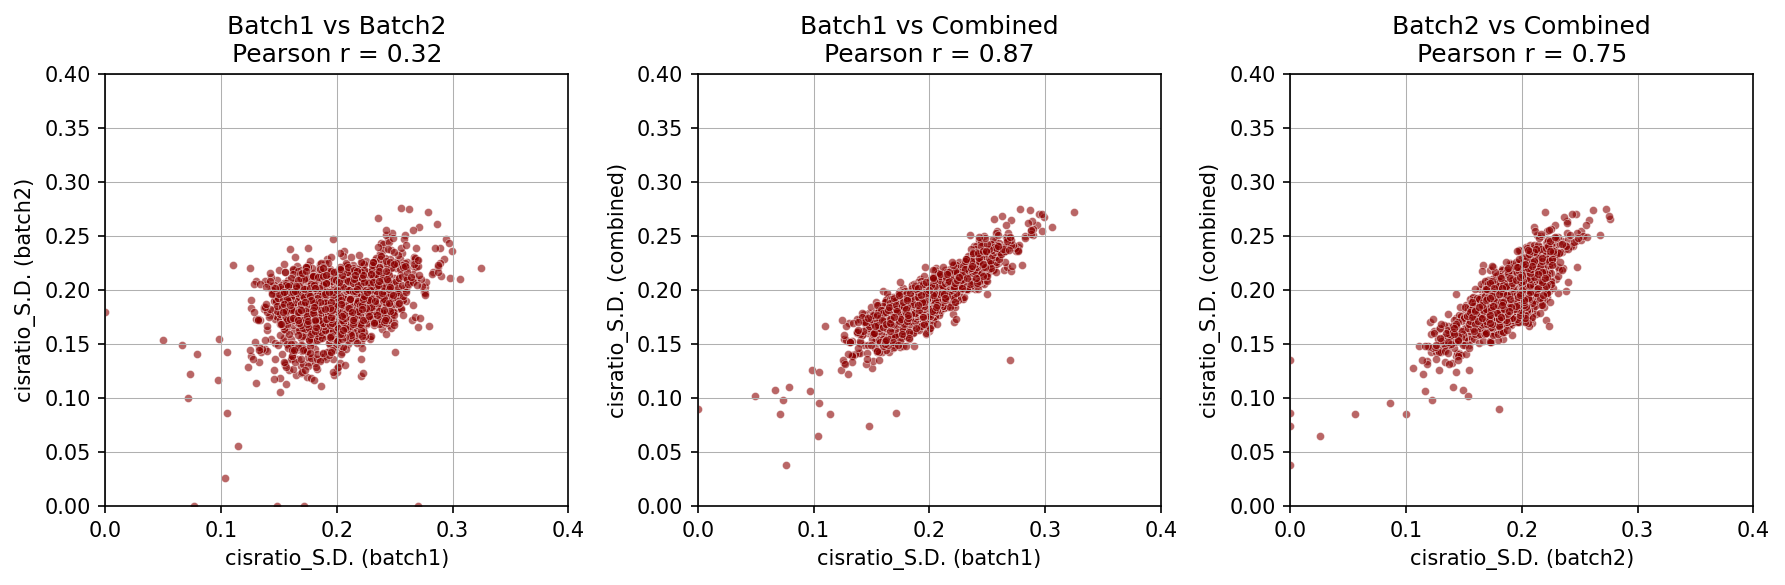

In [64]:
#plot scatter plot
from scipy.stats import pearsonr

# Define the comparisons
comparisons = [
    ("batch1", comp_bin_cisratio_batch1, "batch2", comp_bin_cisratio_batch2, "Batch1 vs Batch2"),
    ("batch1", comp_bin_cisratio_batch1, "combined", comp_bin_cisratio_combine, "Batch1 vs Combined"),
    ("batch2", comp_bin_cisratio_batch2, "combined", comp_bin_cisratio_combine, "Batch2 vs Combined")
]

# Set up the figure
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=150)

for ax, (label_x, df_x, label_y, df_y, title_text) in zip(axes, comparisons):
    df_corr = pd.DataFrame({
        'x': df_x['cisratio_S.D.'],
        'y': df_y['cisratio_S.D.']
    }).replace([np.inf, -np.inf], np.nan).dropna()

    x_clean = df_corr['x']
    y_clean = df_corr['y']

    corr_coef, _ = pearsonr(x_clean, y_clean)

    sns.scatterplot(x=x_clean, y=y_clean, alpha=0.6, s=15, color='darkred', ax=ax)
    ax.set_xlabel(f'cisratio_S.D. ({label_x})')
    ax.set_ylabel(f'cisratio_S.D. ({label_y})')
    ax.set_xlim(0, 0.4)
    ax.set_ylim(0, 0.4)
    ax.set_title(f'{title_text}\nPearson r = {corr_coef:.2f}')
    ax.grid(True, lw=0.5)

plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/S.D._cistotal_all_comparisons.pdf")
plt.show()

# check the histgram of CV; E1 VS Mean of Cisratio in batch_combined ES profile
conclusion: combined plate-based ES skrew the cv of total into higher caused by second batch the overall cv are higher than batch1 --> we decided to use batch1 across five stages to plot in final Fig 3; but we used the integrated H1 cistotal annotation in Fig 1, since Fig1 was isolated H1 annotation without compare to differentiation stages. 

In [ ]:
#plot EGV1 VS cis/total mean using ES combined batch

In [79]:
#create chrom_size df
chrom_size = {
    'chr1': '248956422',    'chr2': '242193529',
    'chr3': '198295559',    'chr4': '190214555',
    'chr5': '181538259',    'chr6': '170805979',
    'chr7': '159345973',    'chr8': '145138636',
    'chr9': '138394717',    'chr10': '133797422',
    'chr11': '135086622',    'chr12': '133275309',
    'chr13': '114364328',    'chr14': '107043718',
    'chr15': '101991189',    'chr16': '90338345',
    'chr17': '83257441',    'chr18': '80373285',
    'chr19': '58617616',    'chr20': '64444167',
    'chr21': '46709983',    'chr22': '50818468',
    'chrX': '156040895',    'chrY': '57227415'}

chrom_size_df = pd.DataFrame(list(chrom_size.items()), columns=['chrom', 'Size'])
# Convert the 'Size' column to integer type
chrom_size_df['Size'] = chrom_size_df ['Size'].astype(int)
chrom_size_df['normalized_ratio'] = sum(chrom_size_df['Size'])/chrom_size_df ['Size']

In [82]:
#load old batch
#read comp_bin_cisratio _normalized into .csv (needs to take care 1M or 2M)
stages2 = ['ES', 'DE', 'HB', 'iHep', 'mHep']
comp_bin_cisratio = {}
contact_dist = 300
# Read each CSV file into a DataFrame and store it in the stage_cis_ratio_Bin_ID_sum dictionary
for stage in stages2:
    file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'    
    df = pd.read_csv(file_path, sep='\t',index_col=0)
    comp_bin_cisratio[stage] = df

In [83]:
#save the old batch
comp_bin_cisratio_old = comp_bin_cisratio.copy()

In [84]:
#replace 'ES' stage using combined batch
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/ES_comp_bin_cisratio_averaged>0.3kb.txt'
df = pd.read_csv(file_path, sep='\t',index_col=0)
comp_bin_cisratio['ES'] = df

# plot E1 VS Mean of cistotal, colored by CV of cistotal (chr2 is used in Fig1)

In [69]:
#split comp_combine table by different chromosomes
def split_df_by_chrom(df):
    # Get unique chromosome values
    unique_chrom_values = df['chrom'].unique()
    
    # Create a dictionary to store the split DataFrames
    split_dfs = {}
    
    # Iterate over unique chromosome values
    for chrom_value in unique_chrom_values:
        # Extract rows with the current chromosome value
        split_df = df[df['chrom'] == chrom_value].copy()
         # Reset index
        split_df.reset_index(drop=True, inplace=True)
        # Store the DataFrame in the dictionary
        split_dfs[chrom_value] = split_df
    return split_dfs

In [85]:
#apply 'split_df_by_chrom' function for integrated new batches
comp_bin_cisratio_arm = {}
for stage in stages2:
    comp_bin_cisratio_arm[stage] = split_df_by_chrom(comp_bin_cisratio[stage])

In [86]:
#apply 'split_df_by_chrom' function for batch 1
comp_bin_cisratio_arm_old = {}
for stage in stages2:
    comp_bin_cisratio_arm_old[stage] = split_df_by_chrom(comp_bin_cisratio_old[stage])

In [89]:
##check the corelationship between cis/tota and EGV

import warnings
warnings.filterwarnings('ignore')

from scipy.stats import pearsonr
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.cm as cml

# Set seaborn context to adjust font size
sns.set_context("talk")

fig = plt.figure(figsize=(20, 75), dpi=150)

num_stages = len(stages2)
num_chrom = len(chrom_size)

# Set up the subplots (adjust rows and columns according to your data)
fig, axes = plt.subplots(nrows=len(chrom_size), ncols=len(stages2), figsize=(20,75))

# Define a normalizer for the color range 0-0.4
norm = mcolors.Normalize(vmin=0.05, vmax=0.30)

for i, stage in enumerate(stages2):
    for j, chrom in enumerate(chrom_size):
        # Drop NaN values from the dataframe
        df = comp_bin_cisratio_arm[stage][chrom].dropna()

        # Plot scatter plot with normalized hue
        scatter = sns.scatterplot(
            data=df, x='E1', y='cisratio_mean', s=15,
            hue='cisratio_S.D.', palette='seismic', legend=False, ax=axes[j, i],
            hue_norm=norm  # Use the normalizer here
        )

        # Plot linear regression line
        sns.regplot(data=df, x='E1', y='cisratio_mean', scatter=False, color='black', line_kws={'linewidth': 1}, ax=axes[j, i])

        axes[j, i].set_xlabel('E1', fontsize=8)
        axes[j, i].set_ylabel('cisratio_mean', fontsize=8)
        axes[j, i].set_title(f'({stage}, Chromosome: {chrom})', fontsize=10)

        # Set y-axis limits to (0.30, 1.0)
        axes[j, i].set_ylim(0.30, 1.0)
        # Set x-axis limits to (-1.1, 1.1)
        axes[j, i].set_xlim(-1.1, 1.1)

        # Calculate Pearson correlation coefficient
        corr_coeff = df['E1'].corr(df['cisratio_mean'])

        # Annotate plot with Pearson correlation coefficient
        axes[j, i].annotate(f"Pearson Corr: {corr_coeff:.2f}", xy=(0.95, 0.8), xycoords='axes fraction', fontsize=10, ha='right')

        # Add colorbar to each subplot
        sm = cm.ScalarMappable(cmap='seismic', norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=axes[j, i], orientation='vertical', shrink=0.5, pad=0.02)
        cbar.set_label('cisratio_S.D.', fontsize=6)
        cbar.ax.tick_params(labelsize=8)

        # Set font size for x and y tick labels
        axes[j, i].tick_params(axis='both', which='major', labelsize=8)

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Cisratio_S.D._VS_EGV_1M_H1_combined_averaged.pdf", 
            format="pdf", bbox_inches="tight")
        
plt.tight_layout()  # Adjust layout
plt.show()

<Figure size 3000x11250 with 0 Axes>

# plot the cv and mean of cis/total for chr2 (used in Fig1)

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/cisratio_S.D._ES_plate_based_combined_chr2_E1_nonNaN_only.pdf


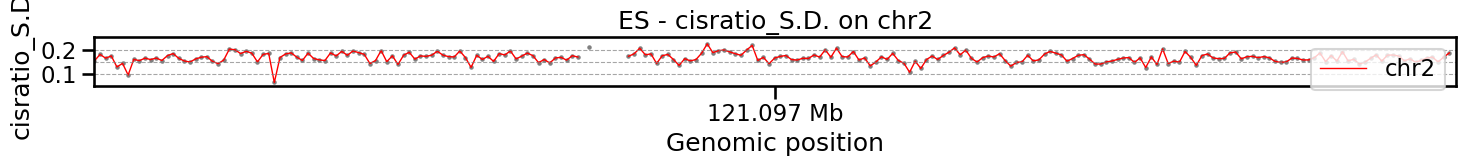

In [104]:
# Plot all cis/total SD across all stages (chr2 only)
# Setup
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"
chroms_to_plot = ['chr2']  # Only chr2
formatter = EngFormatter('b')

for stage in ['ES']:
    df = comp_bin_cisratio_combine.copy()

    # Make cisratio_S.D. blank where E1 is NaN
    df.loc[df["E1"].isna(), "cisratio_S.D."] = np.nan

    # Compute chromosome offset
    offsets = {}
    current_offset = 0
    chrom_boundaries = []
    chrom_ticks = []
    chrom_labels = []

    for chrom in chroms_to_plot:
        chrom_df = df[df['chrom'] == chrom]
        chrom_start = chrom_df['start'].min()
        chrom_end = chrom_df['end'].max()
        chrom_size = chrom_end - chrom_start

        offsets[chrom] = current_offset
        chrom_boundaries.append((chrom, current_offset, current_offset + chrom_size))
        chrom_ticks.append(current_offset + chrom_size // 2)
        chrom_labels.append(chrom)

        current_offset += chrom_size

    # Plot
    fig, ax = plt.subplots(figsize=(15, 2), dpi=100)

    for chrom in chroms_to_plot:
        chrom_df = df[df['chrom'] == chrom].copy()
        offset = offsets[chrom]
        chrom_df['offset_pos'] = chrom_df['start'] + offset

        # Line will break automatically where cisratio_S.D. is NaN
        ax.plot(
            chrom_df['offset_pos'],
            chrom_df['cisratio_S.D.'],
            color='red',
            lw=1,
            label=chrom
        )

        # Scatter only non-NaN E1 / cisratio_S.D. bins
        chrom_df_plot = chrom_df.dropna(subset=["E1", "cisratio_S.D."])

        ax.scatter(
            chrom_df_plot['offset_pos'],
            chrom_df_plot['cisratio_S.D.'],
            color='grey',
            s=3
        )

    # === Added horizontal reference lines ===
    y_lines = [0.05, 0.1, 0.15, 0.2, 0.25]
    for y_val in y_lines:
        ax.axhline(y=y_val, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)

    # Formatting
    ax.set_xticks(chrom_ticks)
    ax.set_xticklabels(chrom_labels)
    ax.xaxis.set_major_formatter(formatter)

    ax.set_ylabel('cisratio_S.D.')
    ax.set_xlabel('Genomic position')
    ax.set_title(f"{stage} - cisratio_S.D. on chr2")
    ax.set_ylim(0.05, 0.25)
    ax.set_xlim(0, current_offset)
    ax.margins(x=0, y=0)
    ax.legend(loc='upper right')

    plt.tight_layout()

    save_path = os.path.join(
        save_dir,
        f"cisratio_S.D._{stage}_plate_based_combined_chr2_E1_nonNaN_only.pdf"
    )

    plt.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved: {save_path}")
    plt.show()

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/cisratio_mean_ES_plate_based_combined_chr2_E1_nonNaN_only.pdf


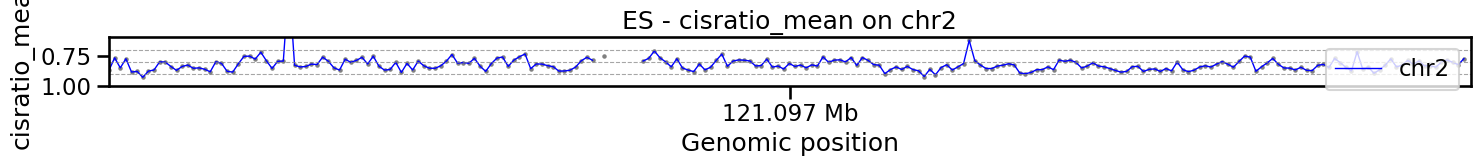

In [101]:
# Plot all cis/total SD across all stages (chr2 only)
# Setup
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"
chroms_to_plot = ['chr2']  # Only chr2
formatter = EngFormatter('b')

for stage in ['ES']:
    df = comp_bin_cisratio_combine.copy()

    # Make cisratio_S.D. blank where E1 is NaN
    df.loc[df["E1"].isna(), "cisratio_mean"] = np.nan

    # Compute chromosome offset
    offsets = {}
    current_offset = 0
    chrom_boundaries = []
    chrom_ticks = []
    chrom_labels = []

    for chrom in chroms_to_plot:
        chrom_df = df[df['chrom'] == chrom]
        chrom_start = chrom_df['start'].min()
        chrom_end = chrom_df['end'].max()
        chrom_size = chrom_end - chrom_start

        offsets[chrom] = current_offset
        chrom_boundaries.append((chrom, current_offset, current_offset + chrom_size))
        chrom_ticks.append(current_offset + chrom_size // 2)
        chrom_labels.append(chrom)

        current_offset += chrom_size

    # Plot
    fig, ax = plt.subplots(figsize=(15, 2), dpi=100)

    for chrom in chroms_to_plot:
        chrom_df = df[df['chrom'] == chrom].copy()
        offset = offsets[chrom]
        chrom_df['offset_pos'] = chrom_df['start'] + offset

        # Line will break automatically where cisratio_S.D. is NaN
        ax.plot(
            chrom_df['offset_pos'],
            chrom_df['cisratio_mean'],
            color='blue',
            lw=1,
            label=chrom
        )

        # Scatter only non-NaN E1 / cisratio_S.D. bins
        chrom_df_plot = chrom_df.dropna(subset=["E1", "cisratio_mean"])

        ax.scatter(
            chrom_df_plot['offset_pos'],
            chrom_df_plot['cisratio_mean'],
            color='grey',
            s=3
        )

    # === Added horizontal reference lines ===
    y_lines = [0.7, 0.8, 0.9,]
    for y_val in y_lines:
        ax.axhline(y=y_val, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)

    # Formatting
    ax.set_xticks(chrom_ticks)
    ax.set_xticklabels(chrom_labels)
    ax.xaxis.set_major_formatter(formatter)

    ax.set_ylabel('cisratio_mean')
    ax.set_xlabel('Genomic position')
    ax.set_title(f"{stage} - cisratio_mean on chr2")
    ax.set_ylim(0.6, 1.0)
    ax.set_ylim(ax.get_ylim()[::-1])  # Reverse y-axis
    ax.set_xlim(0, current_offset)
    ax.margins(x=0, y=0)
    ax.legend(loc='upper right')

    plt.tight_layout()

    save_path = os.path.join(
        save_dir,
        f"cisratio_mean_{stage}_plate_based_combined_chr2_E1_nonNaN_only.pdf"
    )

    plt.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved: {save_path}")
    plt.show()

# plot the batch1(5 stages) used in Fig 3

<Figure size 3000x11250 with 0 Axes>

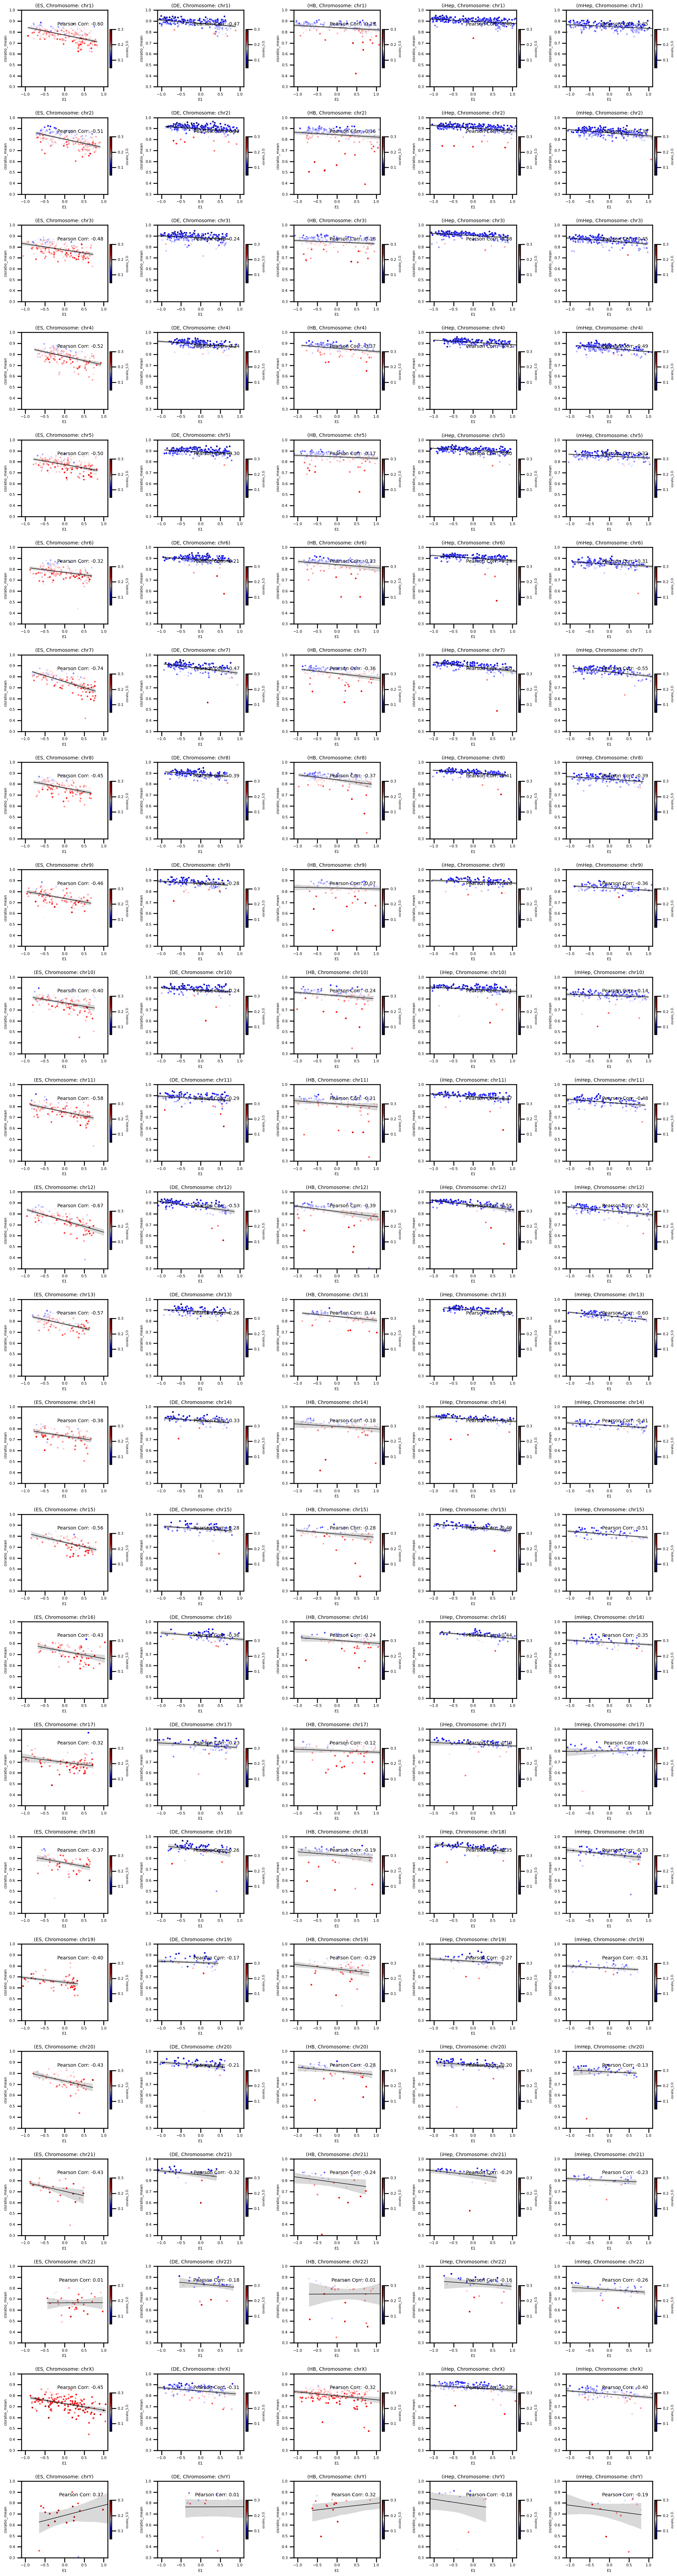

In [ ]:
# Set seaborn context to adjust font size
sns.set_context("talk")

fig = plt.figure(figsize=(20, 75), dpi=150)

num_stages = len(stages2)
num_chrom = len(chrom_size)

# Set up the subplots (adjust rows and columns according to your data)
fig, axes = plt.subplots(nrows=len(chrom_size), ncols=len(stages2), figsize=(20,75))

# Define a normalizer for the color range 0-0.4
norm = mcolors.Normalize(vmin=0.05, vmax=0.3)

for i, stage in enumerate(stages2):
    for j, chrom in enumerate(chrom_size):
        # Drop NaN values from the dataframe
        df = comp_bin_cisratio_arm_old[stage][chrom].dropna()

        # Plot scatter plot with normalized hue
        scatter = sns.scatterplot(
            data=df, x='E1', y='cisratio_mean', s=15,
            hue='cisratio_S.D.', palette='seismic', legend=False, ax=axes[j, i],
            hue_norm=norm  # Use the normalizer here
        )

        # Plot linear regression line
        sns.regplot(data=df, x='E1', y='cisratio_mean', scatter=False, color='black', line_kws={'linewidth': 1}, ax=axes[j, i])

        axes[j, i].set_xlabel('E1', fontsize=8)
        axes[j, i].set_ylabel('cisratio_mean', fontsize=8)
        axes[j, i].set_title(f'({stage}, Chromosome: {chrom})', fontsize=10)

        # Set y-axis limits to (0.30, 1.0)
        axes[j, i].set_ylim(0.30, 1.0)
        # Set x-axis limits to (-1.1, 1.1)
        axes[j, i].set_xlim(-1.1, 1.1)

        # Calculate Pearson correlation coefficient
        corr_coeff = df['E1'].corr(df['cisratio_mean'])

        # Annotate plot with Pearson correlation coefficient
        axes[j, i].annotate(f"Pearson Corr: {corr_coeff:.2f}", xy=(0.95, 0.8), xycoords='axes fraction', fontsize=10, ha='right')

        # Add colorbar to each subplot
        sm = cm.ScalarMappable(cmap='seismic', norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=axes[j, i], orientation='vertical', shrink=0.5, pad=0.02)
        cbar.set_label('cisratio_S.D.', fontsize=6)
        cbar.ax.tick_params(labelsize=8)

        # Set font size for x and y tick labels
        axes[j, i].tick_params(axis='both', which='major', labelsize=8)

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Cisratio_S.D._VS_EGV_1M_batches1.pdf", 
            format="pdf", bbox_inches="tight")
        
plt.tight_layout()  # Adjust layout
plt.show()

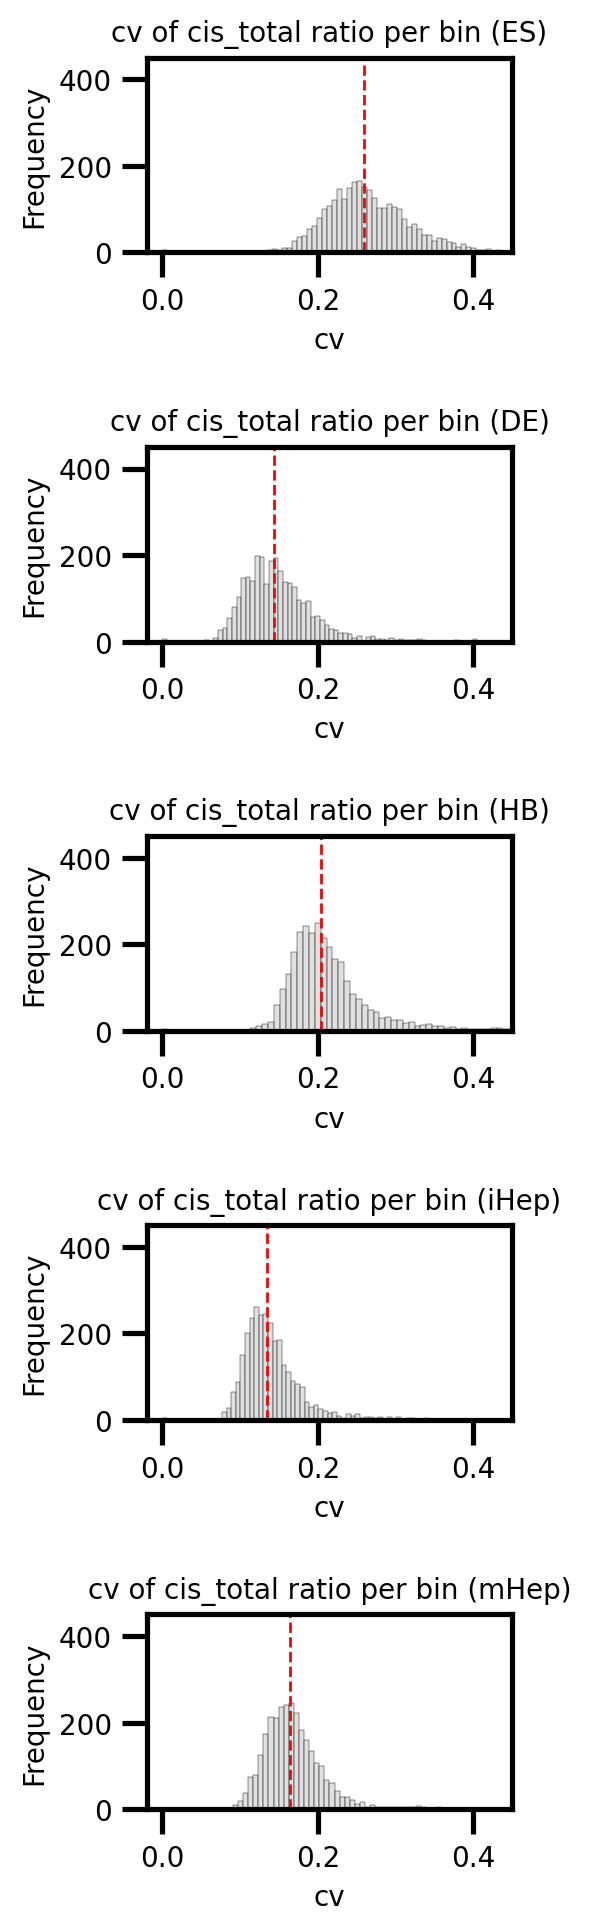

In [91]:
#plot the old batches
#histgram show cv
# Set up the subplots
fig, axes = plt.subplots(nrows=len(stages2), ncols=1, figsize=(3, 10), dpi=200)

# Iterate over stages2
for i, stage in enumerate(stages2):
    # Access the cosine similarity DataFrame
    df = comp_bin_cisratio_old[stage].copy()
#    df = comp_bin_cisratio2[plate][stage].copy()
    median = df['cisratio_cv'].median()
    
    # Plot the histogram on the corresponding subplot
    sns.histplot(df['cisratio_cv'], bins=100, kde=False, color='lightgrey', alpha=0.7, ax=axes[i])
    # Set x-axis limits from 0 to 1
    axes[i].set_xlim(-0.02, 0.45)
    axes[i].set_ylim(0, 450)
#    axes[i].set_title(f'cv of cis_total ratio per bin ({stage} of {plate})', fontsize=10)
    axes[i].set_title(f'cv of cis_total ratio per bin ({stage})', fontsize=10)

    axes[i].set_xlabel('cv', fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)
    
    axes[i].axvline(x=median, color='red', linestyle='--', lw = 1)
    
    # Set font size for x and y tick labels
    axes[i].tick_params(axis='both', which='major', labelsize=10)
    
# Adjust layout
plt.tight_layout()

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_cv_perbin_1M_batches1.pdf", 
            format="pdf", bbox_inches="tight")


plt.show()

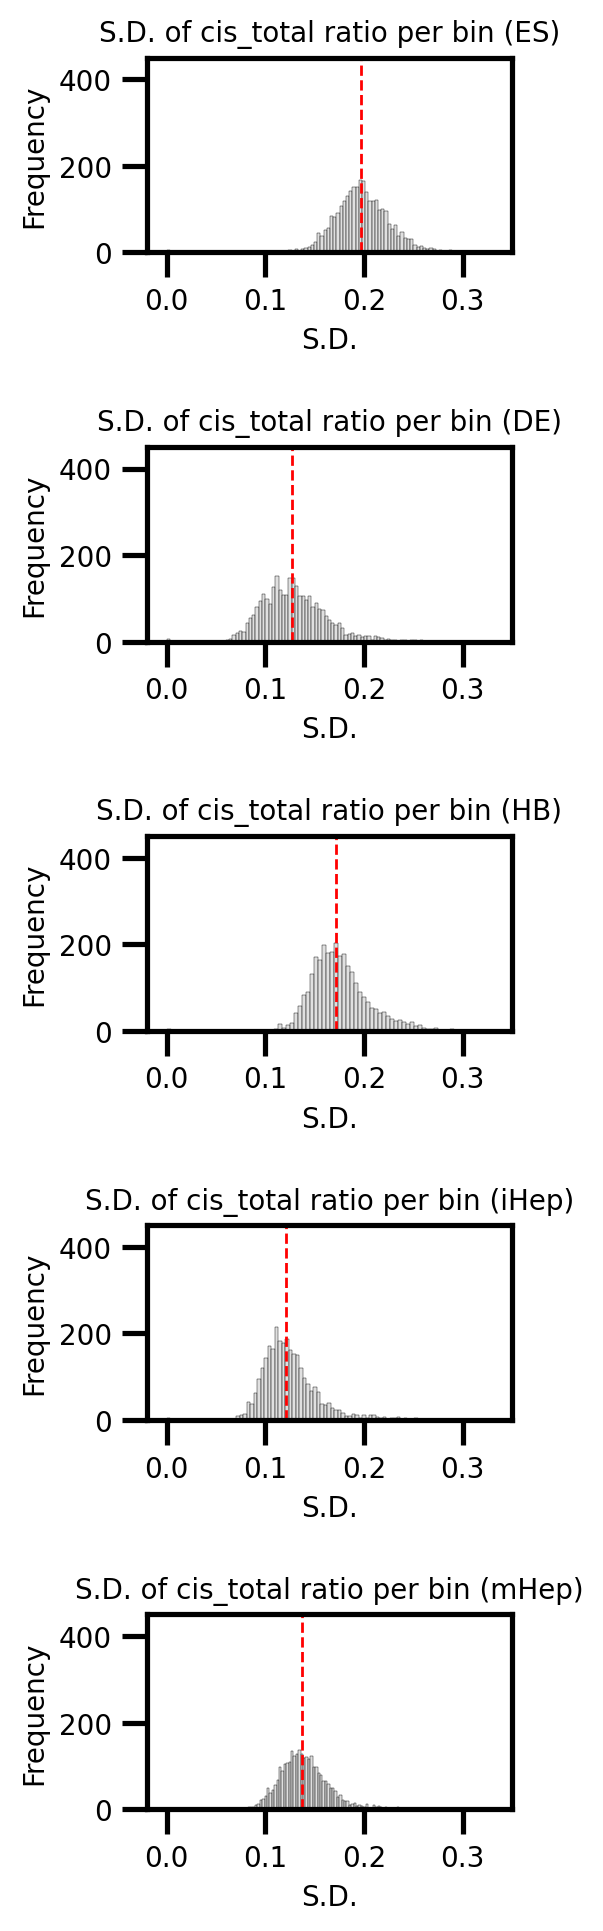

In [94]:
#plot the old batches
#histgram show S.D.
# Set up the subplots
fig, axes = plt.subplots(nrows=len(stages2), ncols=1, figsize=(3, 10), dpi=200)

# Iterate over stages2
for i, stage in enumerate(stages2):
    # Access the cosine similarity DataFrame
    df = comp_bin_cisratio_old[stage].copy()
#    df = comp_bin_cisratio2[plate][stage].copy()
    median = df['cisratio_S.D.'].median()
    
    # Plot the histogram on the corresponding subplot
    sns.histplot(df['cisratio_S.D.'], bins=100, kde=False, color='lightgrey', alpha=0.7, ax=axes[i])
    # Set x-axis limits from 0 to 1
    axes[i].set_xlim(-0.02, 0.35)
    axes[i].set_ylim(0, 450)
#    axes[i].set_title(f'cv of cis_total ratio per bin ({stage} of {plate})', fontsize=10)
    axes[i].set_title(f'S.D. of cis_total ratio per bin ({stage})', fontsize=10)

    axes[i].set_xlabel('S.D.', fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)
    
    axes[i].axvline(x=median, color='red', linestyle='--', lw = 1)
    
    # Set font size for x and y tick labels
    axes[i].tick_params(axis='both', which='major', labelsize=10)
    
# Adjust layout
plt.tight_layout()

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_S.D._perbin_1M_batches1.pdf", 
            format="pdf", bbox_inches="tight")


plt.show()